# GreenShift: results notebook

Carbon-aware scheduling of nightly Spark batch jobs on the GB grid (release 22:00, hard deadline 07:00 UK).
This notebook reads the backtest the pipeline produced and **recomputes the headline numbers from the raw rows**,
then checks them against `results/report_summary.json`, the file the report and the website are built from.
Every number below is computed here; nothing is typed in by hand.

**Run it:** `python scripts/run_all.py --skip-measure` (or `docker compose run --rm pipeline`) regenerates the
backtest and re-executes this notebook. To run it on its own: `jupyter nbconvert --to notebook --execute --inplace notebooks/results.ipynb`.

Conventions used throughout:
- **% saved** = 1 − Σ policy grams / Σ cron (P0) grams, pooled over all jobs and nights. Noisy-forecast rows are averaged over the 10 seeds within a night first.
- Every gram is scored with the grid's **actual** carbon intensity; the scheduler only ever saw the forecast named in the row.
- **Delay** = a job's completion time minus the same job's completion under cron.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
RESULTS = ROOT / "results"
measured = (RESULTS / "measurements.csv").exists()
SRC = RESULTS if measured else RESULTS / "validation_placeholder"

summary = json.loads((RESULTS / "report_summary.json").read_text())
eda = json.loads((RESULTS / "eda_carbon_summary.json").read_text())
verification = json.loads((SRC / "verification.json").read_text())
bt = pd.read_parquet(SRC / "backtest.parquet")

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Backtest: {len(bt):,} rows (2024-2025, every policy, forecast mode and capacity)")
print(f"Summary generated {summary['generated_utc']}, backtest SHA-256 {summary['backtest_sha256'][:16]}…")

Backtest: 437,448 rows (2024-2025, every policy, forecast mode and capacity)
Summary generated 2026-11-13T05:13Z, backtest SHA-256 b5454c0f944e0a73…


## 1. The nightly jobs

Five TPC-DS-derived Spark jobs with modelled lengths. Every job has the same energy, so results are reported as percentages.

In [2]:
jobs = pd.DataFrame(summary["jobs"])
jobs["length_min"] = jobs["duration_slots"] * 30
jobs[["name", "duration_slots", "length_min", "interruptible"]]

,name,duration_slots,length_min,interruptible
0,daily_sales_report,1,30,False
1,customer_analytics,2,60,False
2,inventory_supply_chain,2,60,False
3,cross_channel_promo,4,120,True
4,returns_audit,2,60,False


## 2. Headline: CO₂ saved against cron, recomputed from raw rows

In [3]:
nightly = bt[(bt.scenario == "nightly") & (bt.policy != "P0")]

def pooled_saving(frame, keys):
    per_seed = frame.groupby([*keys, "night", "seed"])[["emissions_g", "baseline_emissions_g"]].sum()
    per_night = per_seed.groupby([*keys, "night"]).mean()          # average noisy seeds within a night
    tot = per_night.groupby(keys).sum()
    return (100 * (1 - tot.emissions_g / tot.baseline_emissions_g)).rename("saved_pct")

keys = ["capacity_k", "policy", "forecast_mode"]
mine = pooled_saving(nightly, keys).to_frame()
mine["median_delay_min"] = nightly.groupby(keys).delay_min.median()
mine["p95_delay_min"] = nightly.groupby(keys).delay_min.quantile(0.95)
mine["deadline_misses"] = nightly.groupby(keys).deadline_met.apply(lambda s: int((~s).sum()))

published = pd.DataFrame(summary["table1"]).set_index(keys)
mine["published_pct"] = published["saved_pct"]
mine["95% CI (published)"] = published.apply(lambda r: f"[{r.ci_low:.2f}, {r.ci_high:.2f}]", axis=1)
assert np.allclose(mine.saved_pct.round(2), mine.published_pct, atol=0.005), "recomputed savings differ from the report"
assert (mine.median_delay_min == published.delay_median_min).all() and np.allclose(mine.p95_delay_min, published.delay_p95_min)
print("Recomputed % saved, median and p95 delay match report_summary.json for all", len(mine), "rows.")
mine

Recomputed % saved, median and p95 delay match report_summary.json for all 18 rows.


saved_pct  median_delay_min  p95_delay_min  \
capacity_k policy forecast_mode                                               
1          P2     api                 5.09             150.0          420.0   
                  noisy               6.73             120.0          390.0   
                  oracle              7.68              90.0          390.0   
           P3     api                 5.04             180.0          420.0   
                  noisy               6.50             120.0          390.0   
                  oracle              7.59             120.0          390.0   
           P4     api                 5.09             150.0          420.0   
                  noisy               6.73             120.0          390.0   
                  oracle              7.68              90.0          390.0   
2          P2     api                 9.87             210.0          450.0   
                  noisy              12.02             180.0          420.0   
                  oracle             13.14             180.0          390.0   
           P3     api                 9.86             240.0          450.0   
                  noisy              12.02             210.0          420.0   
                  oracle             13.33             180.0          390.0   
           P4     api                 9.87             210.0          450.0   
                  noisy              12.02             180.0          420.0   
                  oracle             13.14             180.0          390.0   

                                 deadline_misses  published_pct  \
capacity_k policy forecast_mode                                   
1          P2     api                          0           5.09   
                  noisy                        0           6.73   
                  oracle                       0           7.68   
           P3     api                          0           5.04   
                  noisy                        0           6.50   
                  oracle                       0           7.59   
           P4     api                          0           5.09   
                  noisy                        0           6.73   
                  oracle                       0           7.68   
2          P2     api                          0           9.87   
                  noisy                        0          12.02   
                  oracle                       0          13.14   
           P3     api                          0           9.86   
                  noisy                        0          12.02   
                  oracle                       0          13.33   
           P4     api                          0           9.87   
                  noisy                        0          12.02   
                  oracle                       0          13.14   

                                95% CI (published)  
capacity_k policy forecast_mode                     
1          P2     api                 [4.52, 5.70]  
                  noisy               [6.17, 7.29]  
                  oracle              [7.10, 8.25]  
           P3     api                 [4.45, 5.66]  
                  noisy               [5.99, 7.09]  
                  oracle              [7.02, 8.18]  
           P4     api                 [4.53, 5.72]  
                  noisy               [6.14, 7.32]  
                  oracle              [7.10, 8.26]  
2          P2     api                [9.00, 10.79]  
                  noisy             [11.14, 12.89]  
                  oracle            [12.29, 14.04]  
           P3     api                [8.97, 10.75]  
                  noisy             [11.16, 12.90]  
                  oracle            [12.43, 14.27]  
           P4     api                [8.99, 10.76]  
                  noisy             [11.19, 12.92]  
                  oracle            [12.23, 14.06]

In [4]:
h = summary["headline"]
print(f"Headline (P4, k=1, real NESO forecast): {h['api']['saved_pct']:.2f}% saved "
      f"[95% CI {h['api']['ci_low']:.2f} to {h['api']['ci_high']:.2f}], "
      f"median delay {h['api']['delay_median_min']/60:.1f} h, p95 {h['api']['delay_p95_min']/60:.1f} h")
print(f"Perfect-forecast ceiling (oracle): {h['oracle']['saved_pct']:.2f}%")
print(f"Deadline misses across all {len(bt):,} rows: {int((~bt.deadline_met).sum())}")

Headline (P4, k=1, real NESO forecast): 5.09% saved [95% CI 4.53 to 5.72], median delay 2.5 h, p95 7.0 h
Perfect-forecast ceiling (oracle): 7.68%
Deadline misses across all 437,448 rows: 0


## 3. Independent audit

`scheduler/verification.py` re-derives every row from the slot table and the raw actual series, without using
the scheduler's own code.

In [5]:
{k: verification[k] for k in ["status", "rows", "plans", "deadline_misses", "capacity_violations",
                               "actual_accounting_rows_checked", "energy_conserved"]}

{'status': 'passed',
 'rows': 437448,
 'plans': 157512,
 'deadline_misses': 0,
 'capacity_violations': 0,
 'actual_accounting_rows_checked': 437448,
 'energy_conserved': True}

## 4. Savings against added delay

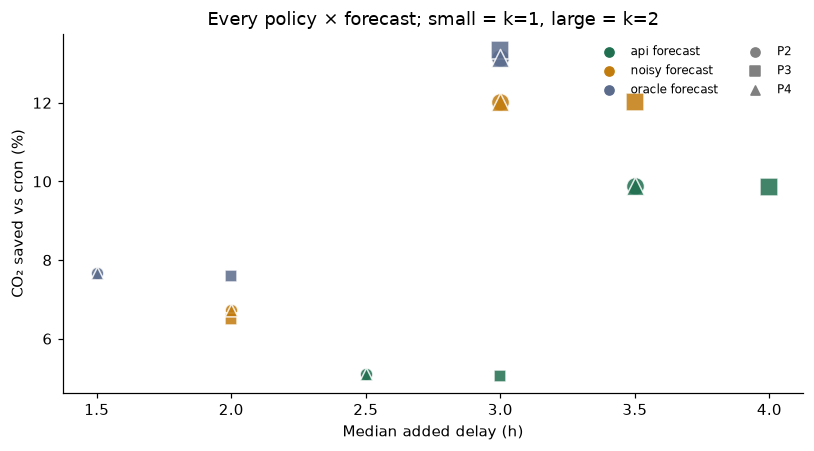

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
marker = {"P2": "o", "P3": "s", "P4": "^"}
colour = {"api": "#1f6f50", "noisy": "#c27c0e", "oracle": "#5b6b8c"}
for (k, pol, mode), r in mine.iterrows():
    ax.scatter(r.median_delay_min / 60, r.saved_pct, marker=marker[pol], color=colour[mode],
               s=70 if k == 1 else 140, alpha=0.85, edgecolor="white")
for mode, c in colour.items():
    ax.scatter([], [], color=c, label=f"{mode} forecast")
for pol, m in marker.items():
    ax.scatter([], [], color="grey", marker=m, label=pol)
ax.set_xlabel("Median added delay (h)"); ax.set_ylabel("CO₂ saved vs cron (%)")
ax.set_title("Every policy × forecast; small = k=1, large = k=2")
ax.legend(frameon=False, fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 5. Night by night (P4, k = 1)

The pooled saving hides nights where the forecast pointed to a slot that turned out dirtier than cron's.

Nights: 729 | median night saves 2.44% | API plan emitted more than cron on 26.5% of nights (oracle: 0.0%)


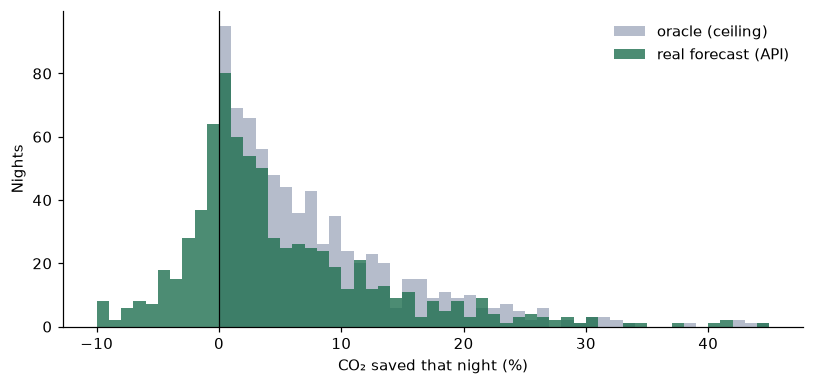

In [7]:
def per_night(mode):
    f = nightly[(nightly.capacity_k == 1) & (nightly.policy == "P4") & (nightly.forecast_mode == mode)]
    g = f.groupby(["night", "seed"])[["emissions_g", "baseline_emissions_g"]].sum().groupby("night").mean()
    return 100 * (1 - g.emissions_g / g.baseline_emissions_g)

api, oracle = per_night("api"), per_night("oracle")
print(f"Nights: {len(api)} | median night saves {api.median():.2f}% | "
      f"API plan emitted more than cron on {100 * (api < -1e-9).mean():.1f}% of nights "
      f"(oracle: {100 * (oracle < -1e-9).mean():.1f}%)")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.arange(-10, 46, 1)
ax.hist(oracle.clip(-10, 45), bins=bins, color="#5b6b8c", alpha=0.45, label="oracle (ceiling)")
ax.hist(api.clip(-10, 45), bins=bins, color="#1f6f50", alpha=0.8, label="real forecast (API)")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("CO₂ saved that night (%)"); ax.set_ylabel("Nights"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Where the savings come from: season and night of the week

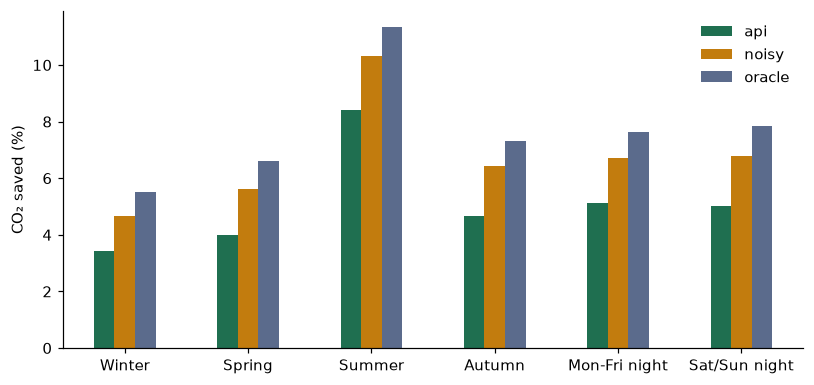

forecast_mode,api,noisy,oracle
group,,,
Winter,3.42,4.65,5.53
Spring,3.98,5.63,6.62
Summer,8.41,10.30,11.34
Autumn,4.65,6.42,7.33
Mon-Fri night,5.12,6.71,7.62
Sat/Sun night,5.03,6.79,7.85


In [8]:
season = pd.DataFrame(summary["by_season"]).pivot(index="group", columns="forecast_mode", values="saved_pct")
season = season.loc[["Winter", "Spring", "Summer", "Autumn"]]
week = pd.DataFrame(summary["by_weekday"]).pivot(index="group", columns="forecast_mode", values="saved_pct")
ax = pd.concat([season, week])[["api", "noisy", "oracle"]].plot.bar(
    figsize=(7.5, 3.6), color=[colour[m] for m in ["api", "noisy", "oracle"]], rot=0)
ax.set_ylabel("CO₂ saved (%)"); ax.set_xlabel(""); ax.legend(frameon=False); plt.tight_layout(); plt.show()
pd.concat([season, week])

## 7. Forecast quality matters: regret against a perfect forecast

In [9]:
fe = eda["forecast_error"]
print(f"NESO national forecast MAE {fe['mae']:.2f} gCO₂/kWh = {fe['mae_pct_of_mean']:.1f}% of the mean "
      f"(bias {fe['bias']:+.2f}, RMSE {fe['rmse']:.2f}, n = {fe['n']:,}); Wiesner et al. assumed 5%.")
regret = pd.DataFrame(summary["table3"]).set_index(["capacity_k", "policy", "forecast_mode"])
regret.rename(columns={"ratio": "share_of_oracle_saving"})

NESO national forecast MAE 9.72 gCO₂/kWh = 7.6% of the mean (bias -0.07, RMSE 13.65, n = 35,014); Wiesner et al. assumed 5%.


saved_pct  oracle_pct  share_of_oracle_saving
capacity_k policy forecast_mode                                               
1          P2     api                 5.09        7.68                    0.66
                  noisy               6.73        7.68                    0.88
           P3     api                 5.04        7.59                    0.66
                  noisy               6.50        7.59                    0.86
           P4     api                 5.09        7.68                    0.66
                  noisy               6.73        7.68                    0.88
2          P2     api                 9.87       13.14                    0.75
                  noisy              12.02       13.14                    0.92
           P3     api                 9.86       13.33                    0.74
                  noisy              12.02       13.33                    0.90
           P4     api                 9.87       13.14                    0.75
                  noisy              12.02       13.14                    0.92

## 8. Replication of Wiesner et al. (Middleware '21), Scenario I

One 30-minute job a night, baseline 01:00 UK, policy P2, shifting windows of ±0.5 to ±8 h. The paper reports
4.3% (±2 h) and 7.4% (±8 h) for GB 2020 with a noisy forecast; we use GB 2024-25 data.

In [10]:
wies = bt[(bt.scenario == "wiesner_s1") & (bt.policy == "P2")]
rep = pooled_saving(wies, ["window_h", "forecast_mode"]).unstack()[["api", "noisy", "oracle"]]
pub = pd.DataFrame(summary["table2"]).pivot(index="window_h", columns="forecast_mode", values="saved_pct")
assert np.allclose(rep.round(2), pub[rep.columns], atol=0.005)
rep["paper (GB 2020, noisy)"] = rep.index.map(lambda w: summary["paper_gb"].get(str(float(w))))
rep

forecast_mode,api,noisy,oracle,"paper (GB 2020, noisy)"
window_h,,,,
0.5,0.15,0.94,2.11,NaN
1.0,0.96,2.18,3.88,NaN
2.0,3.03,4.45,6.58,4.3
4.0,3.02,5.90,8.22,NaN
8.0,5.02,10.28,12.74,7.4


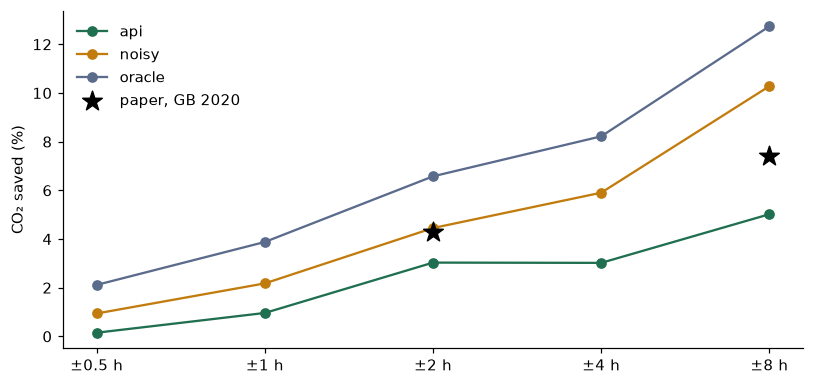

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for mode in ["api", "noisy", "oracle"]:
    ax.plot(rep.index, rep[mode], marker="o", color=colour[mode], label=mode)
paper = {float(k): v for k, v in summary["paper_gb"].items()}
ax.scatter(list(paper), list(paper.values()), marker="*", s=180, color="black", zorder=5, label="paper, GB 2020")
ax.set_xscale("log", base=2); ax.set_xticks(rep.index, [f"±{w:g} h" for w in rep.index])
ax.set_ylabel("CO₂ saved (%)"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 9. Carbon intensity the batch actually ran at

This is the operational term *I* of the Software Carbon Intensity score, `SCI = (E × I + M) / R`.

In [12]:
pd.DataFrame(summary["intensity"]).set_index(["policy", "forecast_mode"])

g_per_kwh
policy forecast_mode           
P0     api                115.6
P4     api                109.7
       noisy              107.8
       oracle             106.7

## 10. Conclusions (computed)

In [13]:
a, o, n = h["api"], h["oracle"], h["noisy"]
k2 = published.loc[(2, "P4", "api")]
r2 = rep.loc[2.0]
print(f"""- With the real forecast, P4 cuts the nightly batch's emissions by {a['saved_pct']:.2f}% (95% CI {a['ci_low']:.2f} to {a['ci_high']:.2f}),
  {o['saved_pct']:.2f}% with a perfect forecast; {int((~bt.deadline_met).sum())} deadline misses in {len(bt):,} rows.
- The typical job finishes {a['delay_median_min']/60:.1f} h later than under cron (p95 {a['delay_p95_min']/60:.1f} h), always before 07:00.
- With two parallel slots (k=2) the saving rises to {k2.saved_pct:.2f}%.
- The real forecast captures {100*a['saved_pct']/o['saved_pct']:.0f}% of the oracle saving; it is off by {fe['mae_pct_of_mean']:.1f}% of the mean on average.
- Replication: ±2 h noisy gives {r2['noisy']:.2f}% against the paper's 4.3%.""")

- With the real forecast, P4 cuts the nightly batch's emissions by 5.09% (95% CI 4.53 to 5.72),
  7.68% with a perfect forecast; 0 deadline misses in 437,448 rows.
- The typical job finishes 2.5 h later than under cron (p95 7.0 h), always before 07:00.
- With two parallel slots (k=2) the saving rises to 9.87%.
- The real forecast captures 66% of the oracle saving; it is off by 7.6% of the mean on average.
- Replication: ±2 h noisy gives 4.45% against the paper's 4.3%.
